# Finding corrections, level by level: L. Yeh's "universal gadget fixing"

> **In short.**
> * **The recipe** (L. Yeh). Unfuse the measurement spiders, separating out the outcome phases $j_1\pi, j_2\pi, \dots$; rewrite the Z-X normal form into an X-Z normal form; the $j\pi$ phases copy across to the right and become $j\pi$ on the outputs. Read the corrections off the rewrite: applying them makes every $j$ act as $j = 0$.
> * **Here.** The recipe as levels of a program, one rewrite per level: `'gpf'` (the Z-X normal form), `'unfuse outcomes'` (each outcome phase on a spider of its own), `'x-z gpf'` (the X-Z normal form), `'unfuse outcomes'` again. The outcome phases left on the outputs are the corrections: $X$ ones in the Z-X form, $Z$ ones in the X-Z form. `find_corrections` reads them the same way; with them applied, the normal form has no outcome phase left. Every level is compared with the circuit in every run its detectors allow.
> * **Two protocols:** teleportation, every step drawn; and the CNOT by lattice surgery of [FindingCorrections.ipynb](FindingCorrections.ipynb), its two normal forms.
> * **How to read the pictures.** Lines are qubits, time runs left to right; green and red dots are Z- and X-spiders; a phase `c[0]` is $\pi$ times that outcome.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CNOT, HAD, Measurement
from zxqec.qprogram import QProgram, find_corrections
from zxqec.codes import surface_code_checks
from zxqec.gpf import equal_for_all_assignments, phases_modulo

## Teleportation

Qubit 0 holds the input; qubits 1 and 2 a Bell pair; qubits 0 and 1 are measured in the Bell basis. PyZX draws each measurement as a Z-spider with an X-spider carrying the outcome, `c[0]` or `c[1]`: the outcome phases are already apart.

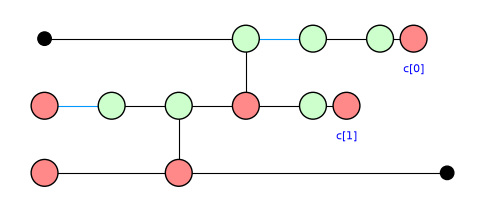

In [2]:
teleport = QProgram(3, bits=2, initial_states={1: '0', 2: '0'})
c = Circuit(3, bit_amount=2)
for gate in [HAD(1), CNOT(1, 2), CNOT(0, 1), HAD(0), Measurement(0, 0), Measurement(1, 1)]:
    c.add_gate(gate)
teleport.add_circuit(c, name='teleport')
circuit_graph = teleport.quantum_graph()
zx.draw_matplotlib(circuit_graph, figsize=(6, 2.5))

In [3]:
zx_form = teleport.level_up(0, 0, 0, 'teleport', rewrite='gpf')
zx_apart = teleport.level_up(zx_form, 0, 0, 'teleport', rewrite='unfuse outcomes')
xz_form = teleport.level_up(zx_apart, 0, 0, 'teleport', rewrite='x-z gpf')
xz_apart = teleport.level_up(xz_form, 0, 0, 'teleport', rewrite='unfuse outcomes')
for level in (zx_form, zx_apart, xz_form, xz_apart):
    print(teleport.describe_level(level))

Level 1 (1 blocks):
  Block 0 'teleport' <rewrite: gpf>: [teleport]
Level 2 (1 blocks):
  Block 0 'teleport' <rewrite: unfuse outcomes>: [teleport]
Level 3 (1 blocks):
  Block 0 'teleport' <rewrite: x-z gpf>: [teleport]
Level 4 (1 blocks):
  Block 0 'teleport' <rewrite: unfuse outcomes>: [teleport]


### Level 1: the Z-X normal form

A Z-spider on the input, an X-spider on the output. The outcomes are now phases on them: `c[0]` on the Z-spider, `c[1]` on the X-spider.

the same map as the circuit in every run: True


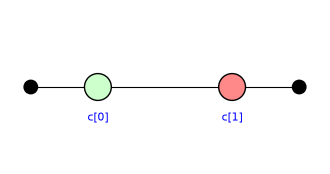

In [4]:
level = teleport.reduced_level(zx_form)
print("the same map as the circuit in every run:", equal_for_all_assignments(circuit_graph, level.graph, constraints=level.detectors))
zx.draw_matplotlib(level.graph, figsize=(4, 2))

### Level 2: the outcome phases apart

Each outcome phase on a spider of its own, of the same colour. The red one with `c[1]` is on the output's X-spider: an $X$ on the output when `c[1]` is 1, the first correction.

the same map as the circuit in every run: True


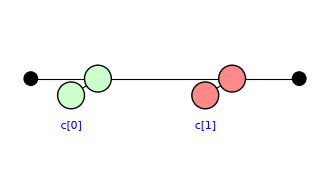

In [5]:
level = teleport.reduced_level(zx_apart)
print("the same map as the circuit in every run:", equal_for_all_assignments(circuit_graph, level.graph, constraints=level.detectors))
zx.draw_matplotlib(level.graph, figsize=(4, 2))

### Level 3: the X-Z normal form

The same map with the colours swapped: an X-spider on the input, a Z-spider on the output. `c[0]` has copied across to the output's Z-spider; `c[1]` is now on the input's X-spider.

the same map as the circuit in every run: True


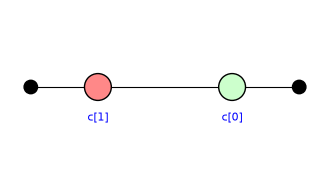

In [6]:
level = teleport.reduced_level(xz_form)
print("the same map as the circuit in every run:", equal_for_all_assignments(circuit_graph, level.graph, constraints=level.detectors))
zx.draw_matplotlib(level.graph, figsize=(4, 2))

### Level 4: the outcome phases apart again

The green one with `c[0]` is on the output: a $Z$ on the output when `c[0]` is 1, the second correction. (The red one with `c[1]` sits on the input, an $X$ before the map; on this map, the identity, it is the same as the $X$ on the output found at level 2.)

the same map as the circuit in every run: True


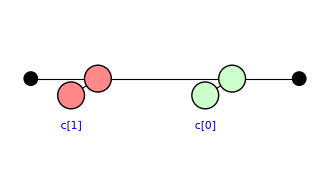

In [7]:
level = teleport.reduced_level(xz_apart)
print("the same map as the circuit in every run:", equal_for_all_assignments(circuit_graph, level.graph, constraints=level.detectors))
zx.draw_matplotlib(level.graph, figsize=(4, 2))

### The corrections, applied

`find_corrections` reads the same two corrections off the two normal forms. Appended as a last stage, the program's Z-X normal form has no outcome phase left: every outcome acts as 0.

X on qubit 2 when c[1] = 1
Z on qubit 2 when c[0] = 1
with them, every run is the run with every outcome 0


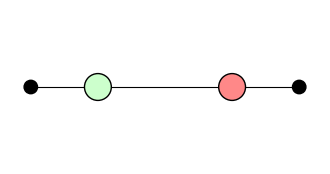

In [8]:
fix = find_corrections(teleport)
print(fix)
c = Circuit(3, bit_amount=2)
for gate in fix.gates():
    c.add_gate(gate)
teleport.add_circuit(c, name='corrections')
corrected = teleport.level_up(0, 0, 1, 'teleport and corrections', rewrite='gpf')
zx.draw_matplotlib(teleport.reduced_level(corrected).graph, figsize=(4, 2))

## A CNOT by lattice surgery

The program of [FindingCorrections.ipynb](FindingCorrections.ipynb), Part 3: three distance-2 surface-code patches, the ancilla A on qubits 0–3, the control C on 4–7, the target T on 8–11; a $ZZ$ merge of C and A, an $XX$ merge of A and T, their split, and A measured. The same four levels; the pictures write each phase modulo the detectors (`phases_modulo`), as `find_corrections` reads them.

In [9]:
A, C_, T_ = [0, 1, 2, 3], [4, 5, 6, 7], [8, 9, 10, 11]
ENCODE = {p: [CNOT(p[1], p[3]), HAD(p[0]), CNOT(p[0], p[1]), CNOT(p[0], p[2]), CNOT(p[0], p[3])] for p in (tuple(A), tuple(C_), tuple(T_))}
surgery = QProgram(17, bits=9, initial_states={**{q: '0' for q in range(17) if q not in (5, 9)}, 1: '+'})
for name, gates in (('encode C and T', ENCODE[tuple(C_)] + ENCODE[tuple(T_)]),
                    ('ancilla |+>', ENCODE[tuple(A)]),
                    ('merge C, A: Z Z', [CNOT(q, 12) for q in (2, 3, 4, 5)] + [Measurement(12, 0)]),
                    ('merge A, T: X X', [g for h, qs, bit in ((13, (1, 8), 1), (14, (3, 10), 2))
                                         for g in [HAD(h)] + [CNOT(h, q) for q in qs] + [HAD(h), Measurement(h, bit)]]),
                    ('split A, T', [g for h, qs, bit in ((15, (1, 3), 3), (16, (8, 10), 4))
                                    for g in [CNOT(q, h) for q in qs] + [Measurement(h, bit)]]),
                    ('measure A', [Measurement(q, 5 + k) for k, q in enumerate(A)])):
    c = Circuit(17, bit_amount=9)
    for gate in gates:
        c.add_gate(gate)
    surgery.add_circuit(c, name=name)
surgery_graph = surgery.quantum_graph()
s_zx = surgery.level_up(0, 0, 5, 'all', rewrite='gpf')
s_zx_apart = surgery.level_up(s_zx, 0, 0, 'all', rewrite='unfuse outcomes')
s_xz = surgery.level_up(s_zx_apart, 0, 0, 'all', rewrite='x-z gpf')
s_xz_apart = surgery.level_up(s_xz, 0, 0, 'all', rewrite='unfuse outcomes')
for level in (s_zx, s_zx_apart, s_xz, s_xz_apart):
    print(level, "the same map as the circuit in every run:",
          equal_for_all_assignments(surgery_graph, surgery.reduced_level(level).graph, constraints=surgery.reduced_level(level).detectors))

1 the same map as the circuit in every run: True


2 the same map as the circuit in every run: True


3 the same map as the circuit in every run: True


4 the same map as the circuit in every run: True


The Z-X normal form with the outcome phases apart (level 2): two Z-spiders on the inputs (C's and T's), X-spiders on the eight outputs (C on top, then T). The red outcome phases sit on T's outputs: on qubit 8 (`c[3]`, the split) and on qubits 9 and 11 (`c[0] + c[3] + c[5] + c[6]`), the $X$ corrections.

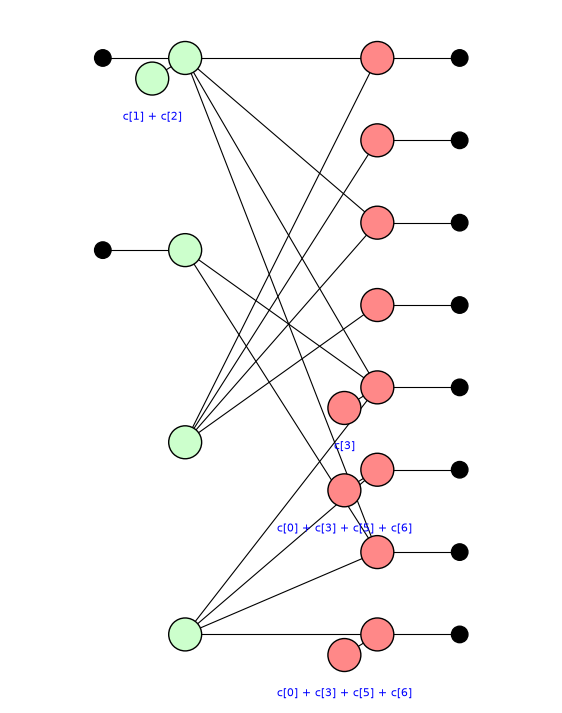

In [10]:
level = surgery.reduced_level(s_zx_apart)
zx.draw_matplotlib(phases_modulo(level.graph, level.detectors), figsize=(7, 9))

The X-Z normal form with the outcome phases apart (level 4): the green outcome phases have copied across to C's outputs, qubits 4 and 7 (`c[1] + c[2]`, the $XX$ merge): the $Z$ corrections. The red ones are now on the left, one on T's input.

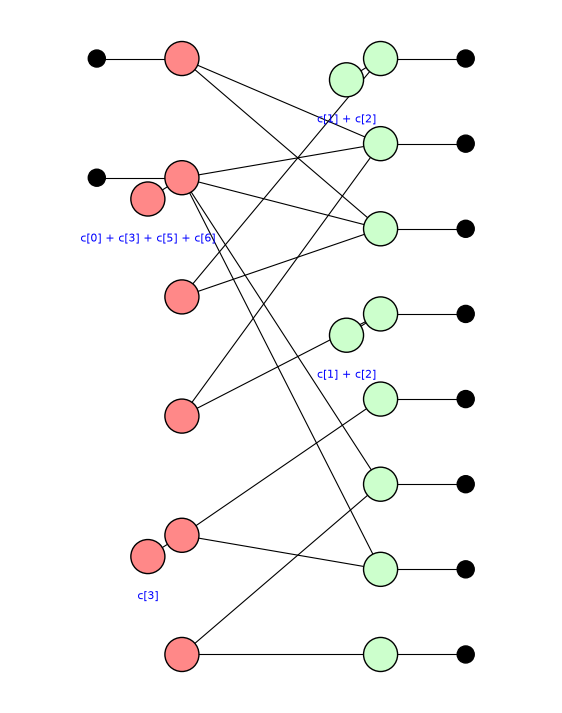

In [11]:
level = surgery.reduced_level(s_xz_apart)
zx.draw_matplotlib(phases_modulo(level.graph, level.detectors), figsize=(7, 9))

`find_corrections` reads the $X$ corrections off level 2, and the $Z$ ones off the X-Z form of the program with the $X$ corrections applied. There they come out on qubits 4 and 5 instead of 4 and 7: the two differ by $Z_5 Z_7$, the second $Z$ check of the patch (`surface_code_checks(2)`, on C's qubits 4–7), so both are the same correction on C's code.

In [12]:
fix = find_corrections(surgery)
print(fix)
print("the Z checks of a patch, on C's qubits 4, 5, 6, 7:")
print(surface_code_checks(2)[1])

X on qubit 8 when c[3] = 1
X on qubit 9 when c[0] + c[3] + c[5] + c[6] = 1
X on qubit 11 when c[0] + c[3] + c[5] + c[6] = 1
Z on qubit 4 when c[1] + c[2] = 1
Z on qubit 5 when c[1] + c[2] = 1
with them, every run is the run with every outcome 0
the Z checks of a patch, on C's qubits 4, 5, 6, 7:
[[1 0 1 0]
 [0 1 0 1]]


## How this differs from the recipe

* PyZX already draws a measurement with its outcome on a spider of its own, so the first step of the recipe is the circuit itself; the normal forms fuse the outcome phases in, and `'unfuse outcomes'` takes them out again to show where they are.
* The recipe's last step, applying the dagger to be left with only the $j\pi$, is not drawn; the tool instead checks that, with the corrections, every run is the run with every outcome 0.
* A correction that the X-Z form puts on an input acts before the protocol; `find_corrections` uses the one the Z-X form puts on the output instead, which is the same on these protocols (Part 1, level 4).

What is not covered: Pauli corrections only, put at the end of the program.